In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score
)

sns.set_theme(style='whitegrid')

In [3]:
path = Path('data/creditcard.csv')
if not path.exists():
    path = Path('anomaly_search/data/creditcard.csv')

data = pd.read_csv(path)
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. EDA

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [5]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [6]:
print('Пропусков:', data.isna().sum().sum())
print('Полных дубликатов:', data.duplicated().sum())
print('Количество операций по классам:')
print(data['Class'].value_counts())

# Долю аномалий используем как экспертную оценку, по условию задания.
contamination = data['Class'].mean()
print(f'Доля мошеннических операций: {contamination:.4%}')

Пропусков: 0
Полных дубликатов: 1081
Количество операций по классам:
Class
0    284315
1       492
Name: count, dtype: int64
Доля мошеннических операций: 0.1727%


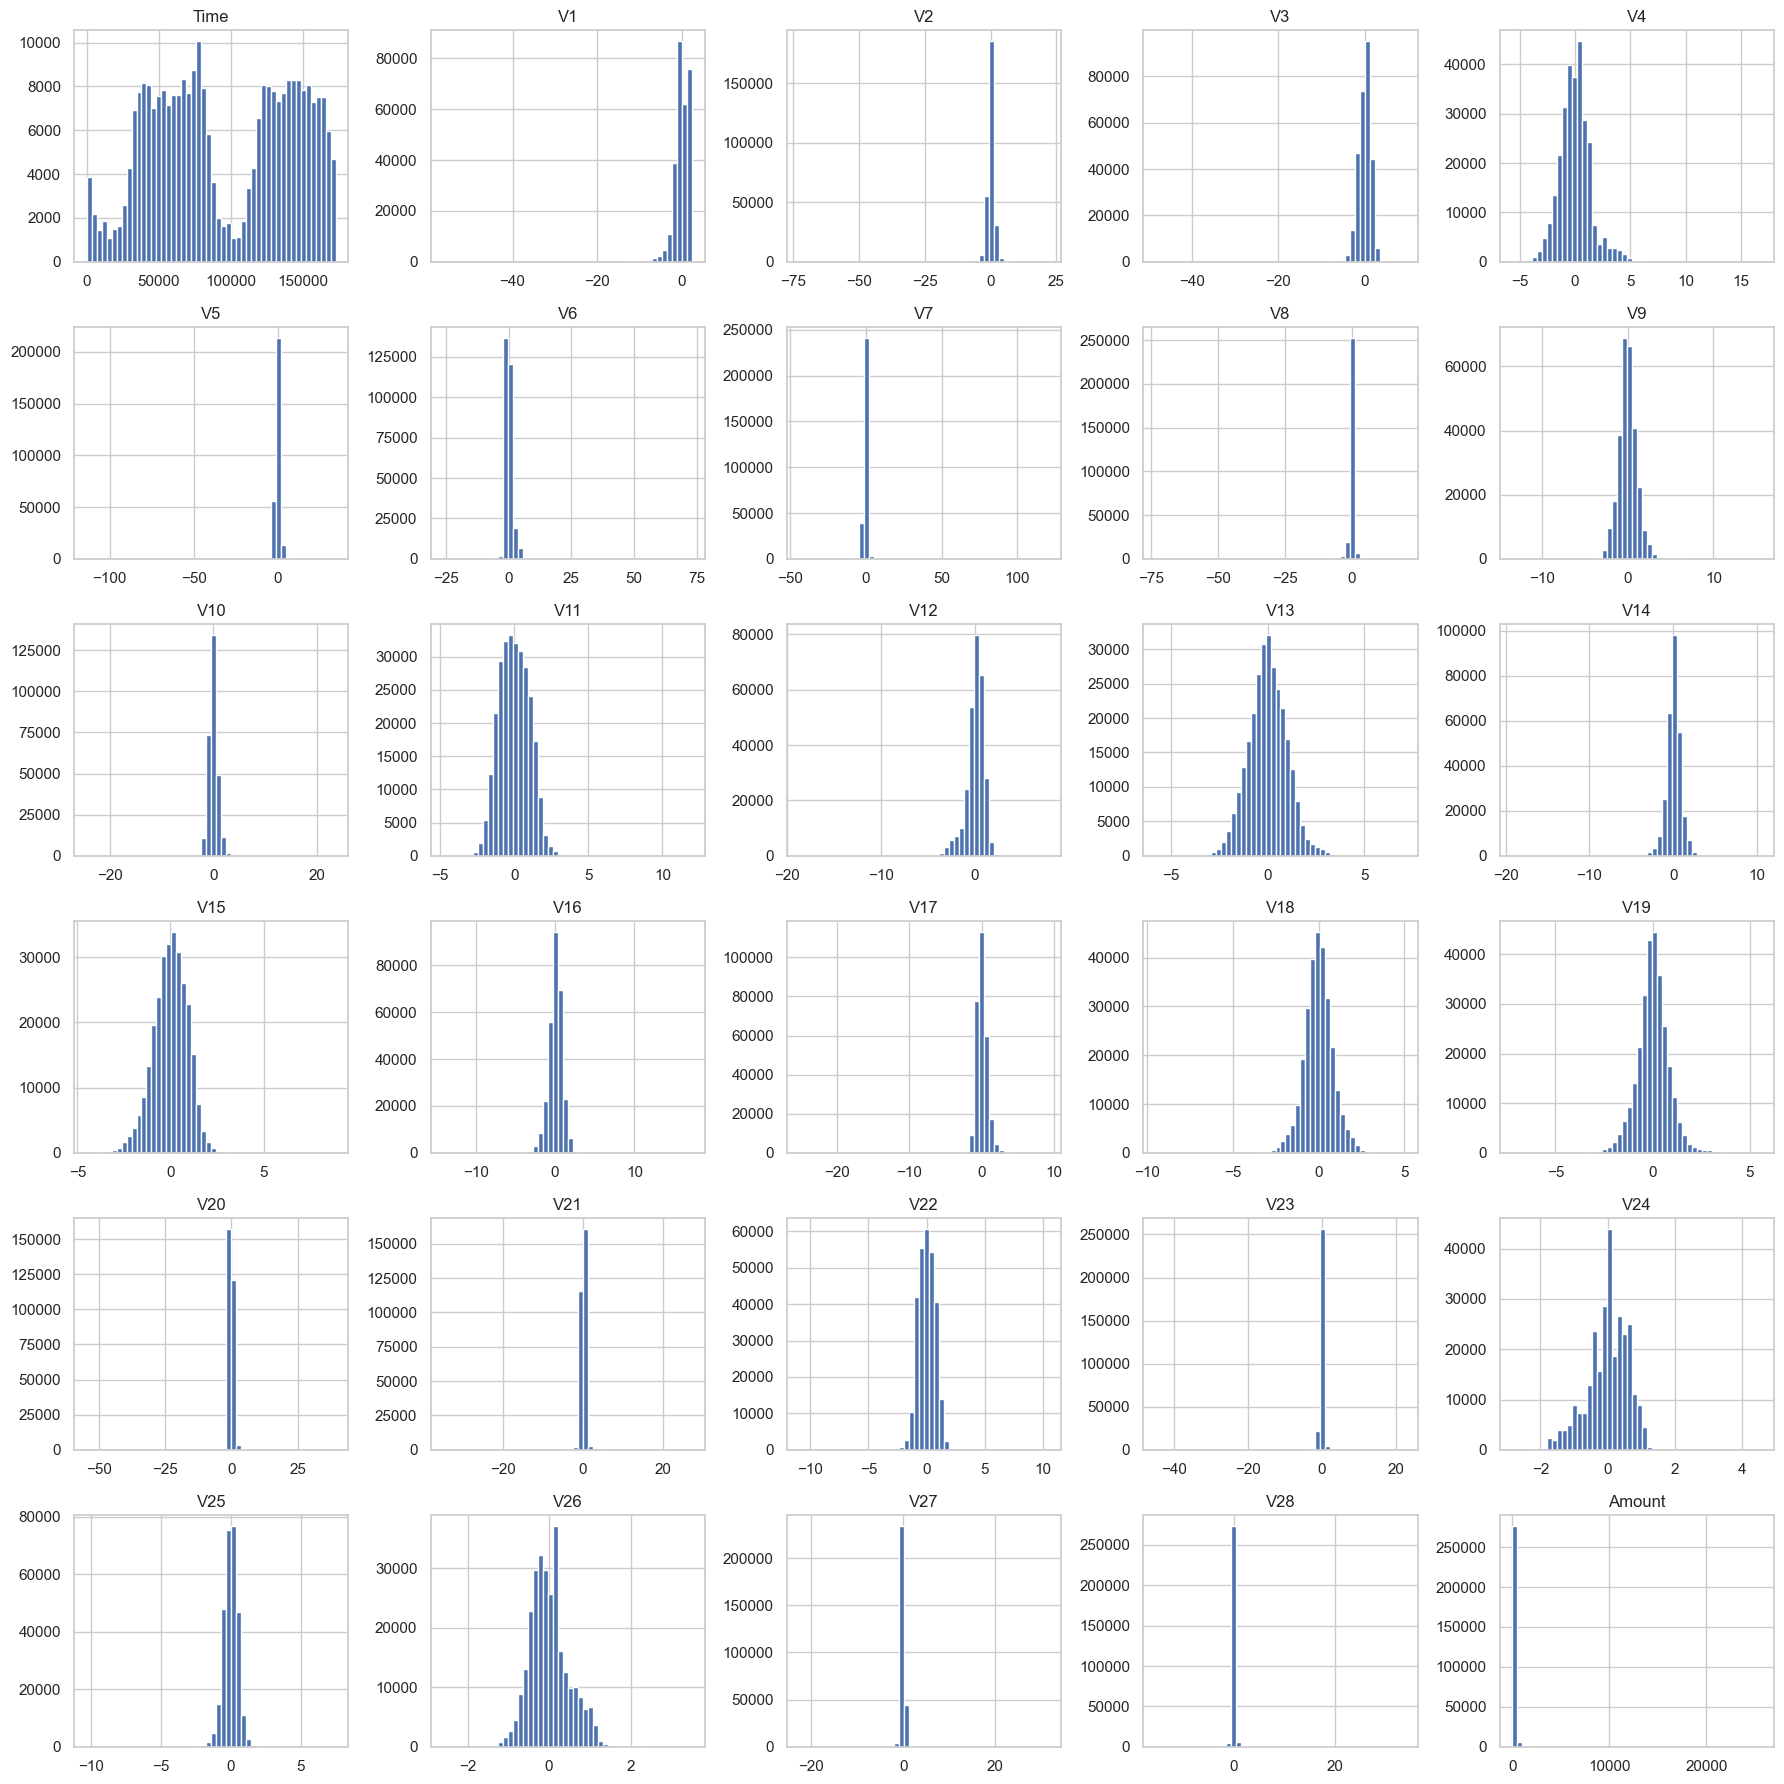

In [7]:
data.drop(columns='Class').hist(bins=50, figsize=(18, 18))
plt.tight_layout()
plt.show()

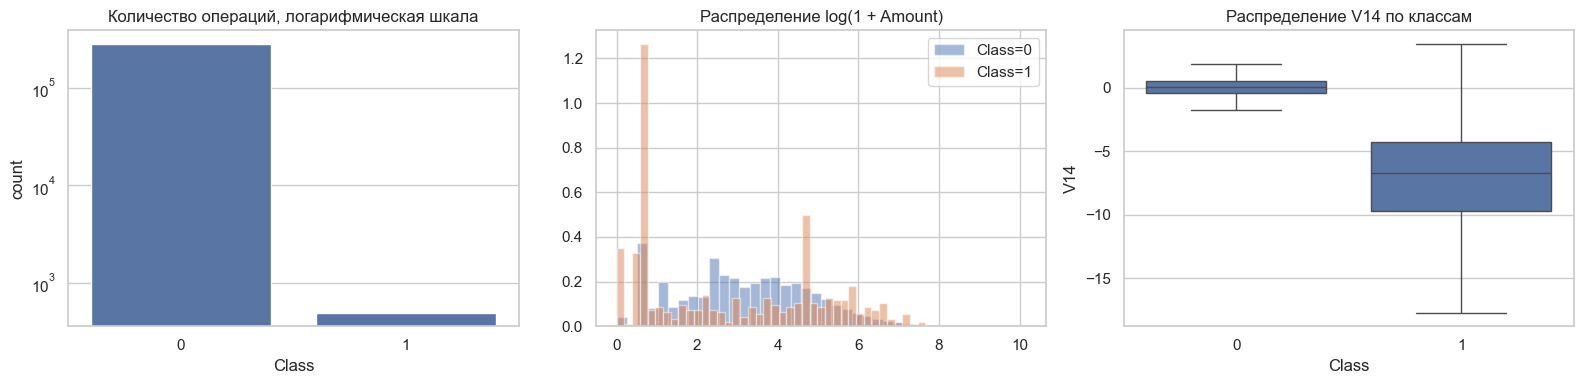

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(data=data, x='Class', ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Количество операций, логарифмическая шкала')

for cls in [0, 1]:
    amounts = data.loc[data['Class'] == cls, 'Amount']
    axes[1].hist(np.log1p(amounts), bins=40, density=True, alpha=0.5, label=f'Class={cls}')
axes[1].set_title('Распределение log(1 + Amount)')
axes[1].legend()

sns.boxplot(data=data, x='Class', y='V14', showfliers=False, ax=axes[2])
axes[2].set_title('Распределение V14 по классам')

plt.tight_layout()
plt.show()

Мошеннических операций всего около 0,17%. Пропусков нет, но есть полные дубли.
Сумма имеет длинный правый хвост, в PCA-компонентах тоже есть крайние значения.
Распределения классов различаются, но перекрываются: необычная операция не обязательно
является мошенничеством. Из-за дисбаланса accuracy почти 100% можно получить,
если всегда предсказывать обычную операцию.

## 2. Подготовка данных

In [9]:
sample = data.drop_duplicates().sample(n=10000, random_state=42).reset_index(drop=True)
X = sample.drop(columns='Class')
y = sample['Class']

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

print('Размер выборки:', X.shape)
print('Мошеннических операций:', y.sum())
print(f'Доля мошенничества в выборке: {y.mean():.2%}')

predictions = {}

Размер выборки: (10000, 30)
Мошеннических операций: 16
Доля мошенничества в выборке: 0.16%


## 3. Простая статистика

In [10]:
mean = X_scaled.mean(axis=0)
std = X_scaled.std(axis=0)

predictions['3 sigma'] = (np.abs(X_scaled - mean) > 3 * std).any(axis=1).astype(int)

q1, q3 = np.quantile(X_scaled, [0.25, 0.75], axis=0)
iqr = q3 - q1
predictions['IQR'] = (
    (X_scaled < q1 - 1.5 * iqr) | (X_scaled > q3 + 1.5 * iqr)
).any(axis=1).astype(int)

## 4. Методы на основе расстояний

In [11]:
center = X_scaled.mean(axis=0)

euclidean_distance = np.sqrt(((X_scaled - center) ** 2).sum(axis=1))
threshold = np.quantile(euclidean_distance, 1 - contamination)
predictions['Euclidean'] = (euclidean_distance > threshold).astype(int)

manhattan_distance = np.abs(X_scaled - center).sum(axis=1)
threshold = np.quantile(manhattan_distance, 1 - contamination)
predictions['Manhattan'] = (manhattan_distance > threshold).astype(int)

## 5. Local Outlier Factor

In [12]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=contamination)
labels = lof.fit_predict(X_scaled)
predictions['LOF'] = (labels == -1).astype(int)

## 6. Модели поиска аномалий

### One-Class SVM

In [13]:
svm = OneClassSVM(nu=contamination, gamma='scale')
labels = svm.fit_predict(X_scaled)
predictions['One-Class SVM'] = (labels == -1).astype(int)

### Isolation Forest

In [14]:
forest = IsolationForest(n_estimators=100, contamination=contamination, random_state=42)
labels = forest.fit_predict(X_scaled)
predictions['Isolation Forest'] = (labels == -1).astype(int)

## 7. Оценка качества

In [15]:
for name, prediction in predictions.items():
    print(name)
    print(classification_report(y, prediction, labels=[0, 1], digits=3, zero_division=0))

3 sigma
              precision    recall  f1-score   support

           0      1.000     0.871     0.931      9984
           1      0.011     0.938     0.023        16

    accuracy                          0.871     10000
   macro avg      0.506     0.904     0.477     10000
weighted avg      0.998     0.871     0.929     10000

IQR
              precision    recall  f1-score   support

           0      1.000     0.518     0.683      9984
           1      0.003     1.000     0.007        16

    accuracy                          0.519     10000
   macro avg      0.502     0.759     0.345     10000
weighted avg      0.998     0.519     0.682     10000

Euclidean
              precision    recall  f1-score   support

           0      0.998     0.998     0.998      9984
           1      0.000     0.000     0.000        16

    accuracy                          0.997     10000
   macro avg      0.499     0.499     0.499     10000
weighted avg      0.997     0.997     0.997     1000

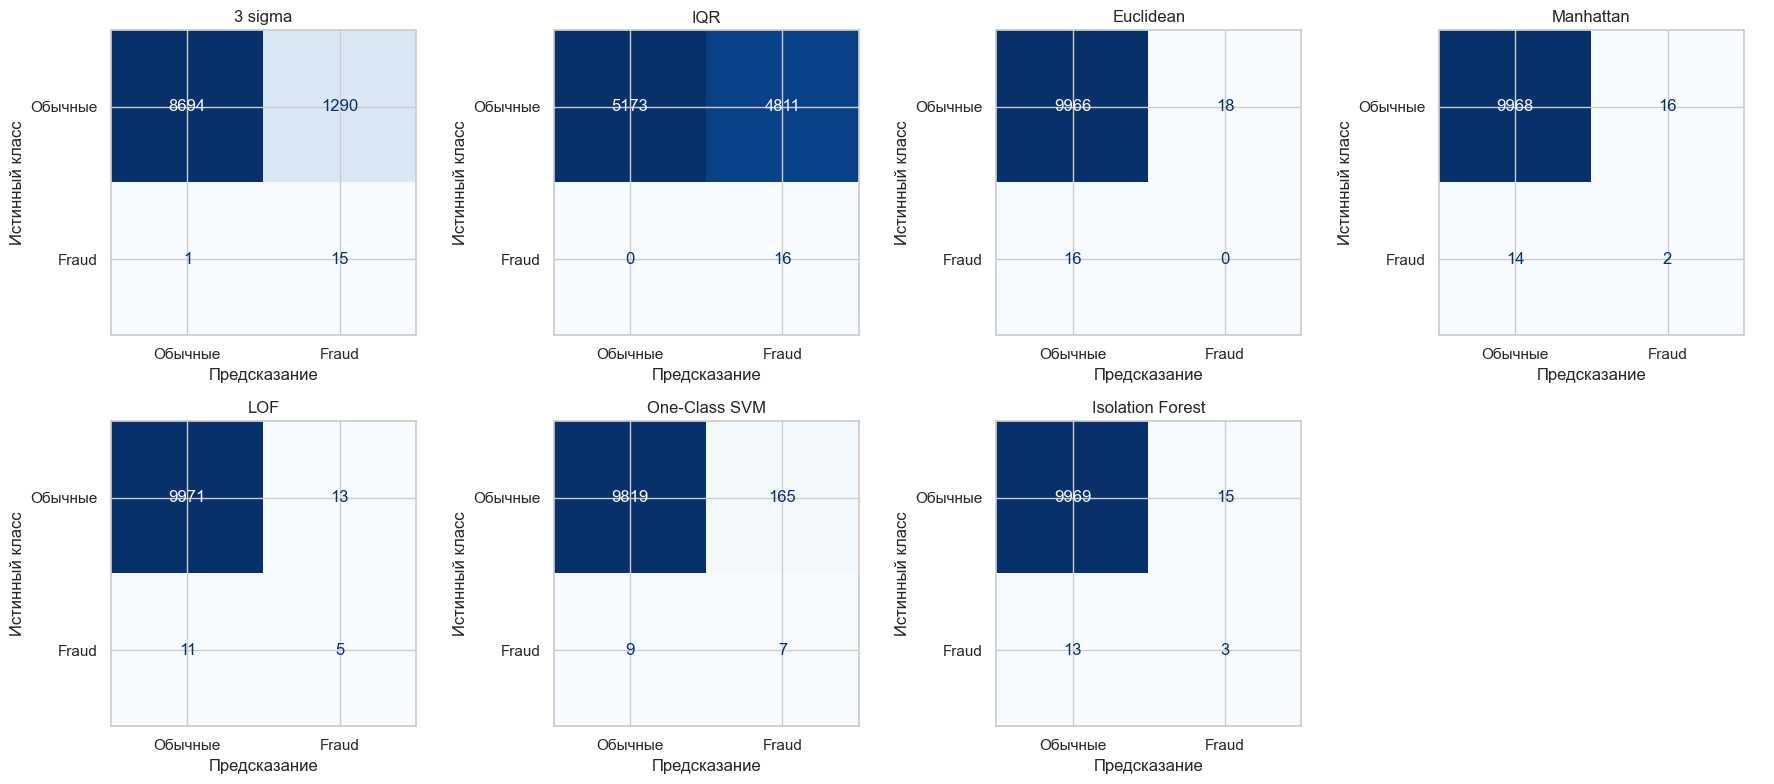

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, (name, prediction) in zip(axes.flat, predictions.items()):
    matrix = confusion_matrix(y, prediction, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=['Обычные', 'Fraud']).plot(
        ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(name)
    ax.set_xlabel('Предсказание')
    ax.set_ylabel('Истинный класс')

axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

In [17]:
results = []
for name, prediction in predictions.items():
    results.append({
        'Метод': name,
        'Precision': precision_score(y, prediction, zero_division=0),
        'Recall': recall_score(y, prediction, zero_division=0),
        'F1': f1_score(y, prediction, zero_division=0),
        'Найдено аномалий': prediction.sum()
    })

results = pd.DataFrame(results).set_index('Метод').sort_values('F1', ascending=False)
results.round(3)

,Precision,Recall,F1,Найдено аномалий
Метод,,,,
LOF,0.278,0.312,0.294,18
Isolation Forest,0.167,0.188,0.176,18
Manhattan,0.111,0.125,0.118,18
One-Class SVM,0.041,0.438,0.074,172
3 sigma,0.011,0.938,0.023,1305
IQR,0.003,1.000,0.007,4827
Euclidean,0.000,0.000,0.000,18


## 8. Визуализация t-SNE

In [18]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X_scaled)

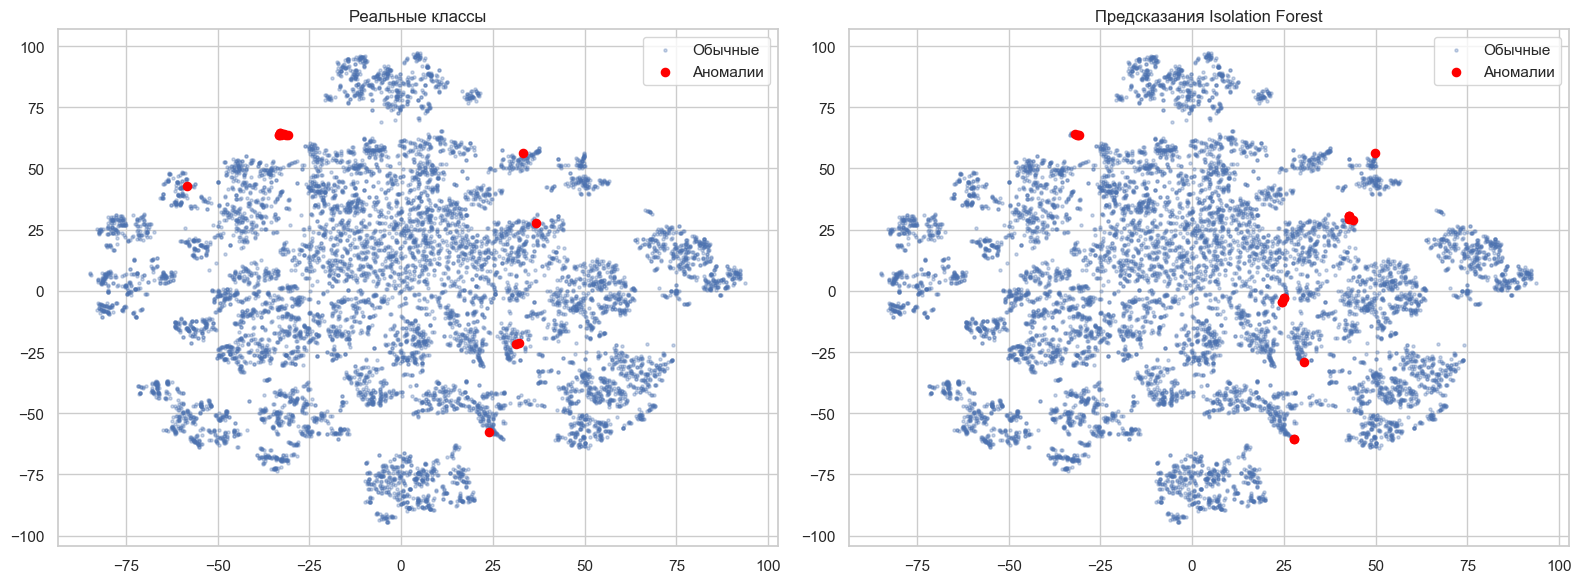

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, labels, title in [
    (axes[0], y.to_numpy(), 'Реальные классы'),
    (axes[1], predictions['Isolation Forest'], 'Предсказания Isolation Forest')
]:
    ax.scatter(X_tsne[labels == 0, 0], X_tsne[labels == 0, 1],
               s=5, alpha=0.3, label='Обычные')
    ax.scatter(X_tsne[labels == 1, 0], X_tsne[labels == 1, 1],
               s=35, color='red', label='Аномалии')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

## Вывод

В исходном датасете 492 мошеннические операции из 284 807, то есть около 0,17%.
Эта доля использовалась для настройки.

На случайной выборке из 10 000 строк оказалось 16 мошенничеств. Лучший F1 получил
LOF: 
precision = 0,278, 
recall = 0,312, 
F1 = 0,294.
Он нашёл 5 из 16 мошенничеств
и дал 13 ложных тревог.
Isolation Forest нашёл 3 из 16, F1 = 0,176.

Правила 3σ и IQR находят почти все мошенничества, но помечают слишком много обычных
операций. Расстояния до среднего работают хуже LOF. Знание доли аномалий помогает
задать порог, но не гарантирует правильное определение мошенничества.

На t-SNE часть мошеннических операций образует небольшую отдельную группу,
другие расположены рядом с обычными транзакциями. Поэтому нельзя сказать, что все
мошенничества лежат далеко от основной массы. К тому же t-SNE искажает расстояния.